In [ ]:
%cd /kaggle/working
!git clone https://@github.com/Backtodagame/Mobility_Aware_for_AGIN.git
%cd /kaggle/working/Mobility_Aware_for_AGIN/Channel_Modeling

/kaggle/working
fatal: destination path 'Mobility_Aware_for_AGIN' already exists and is not an empty directory.
/kaggle/working/Mobility_Aware_for_AGIN/Channel_Modeling


Bắt đầu vẽ biểu đồ phần thưởng
Bắt đầu đánh giá mô hình AI...
Đang tạo file Mp4 (vui lòng chờ)...
✅ Đã lưu Video: /kaggle/working/results/trained_uav_policy.mp4
Đang xử lý dữ liệu để vẽ biểu đồ...


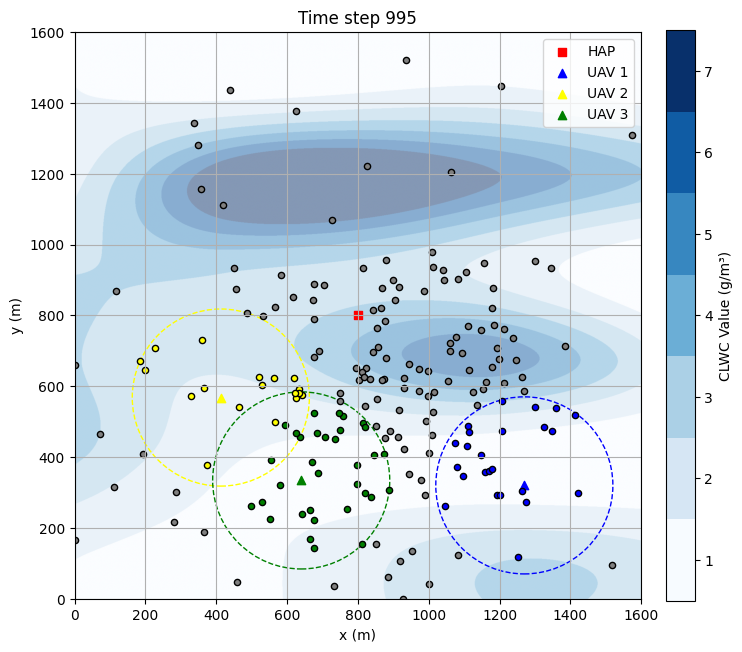

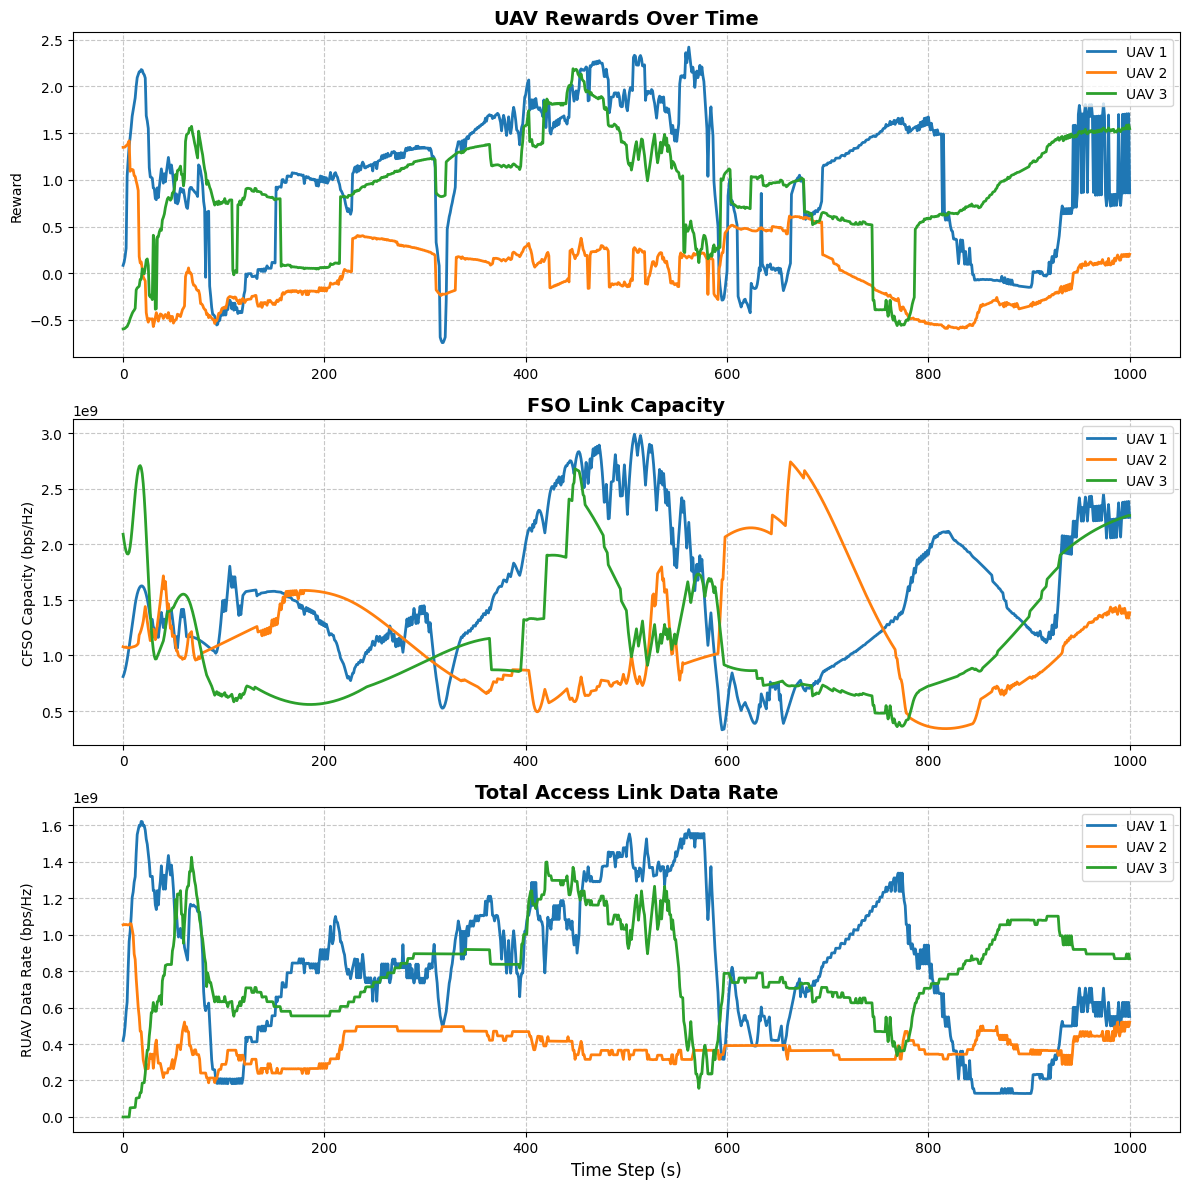

Đang vẽ biểu đồ chồng RUAV lên CFSO...


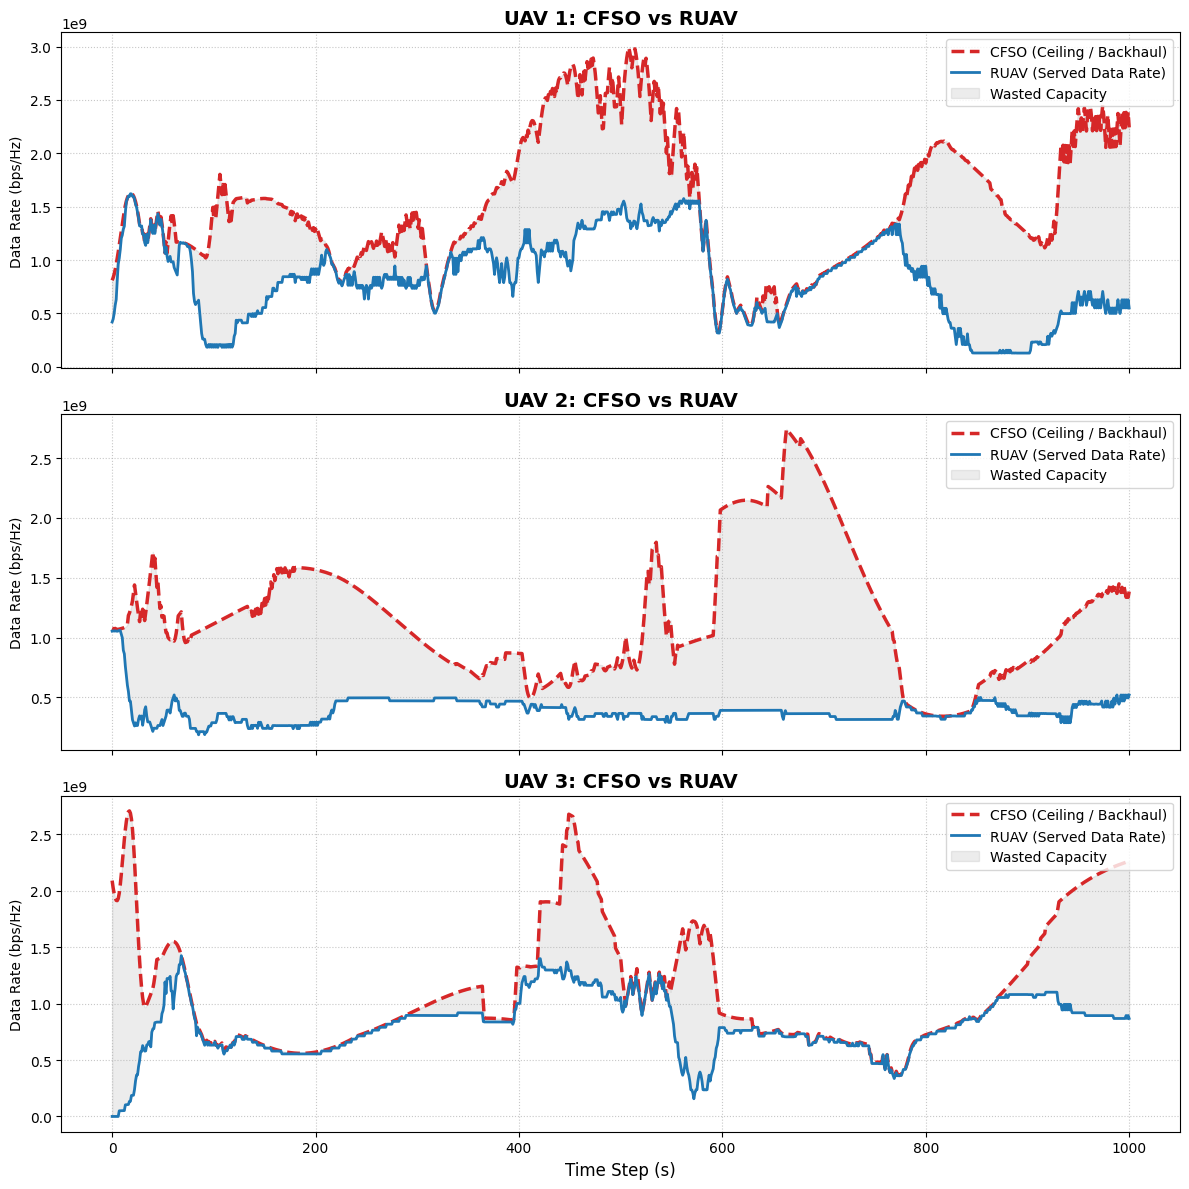

Đang vẽ biểu đồ Tổng dung lượng hệ thống (Total System Capacity)...


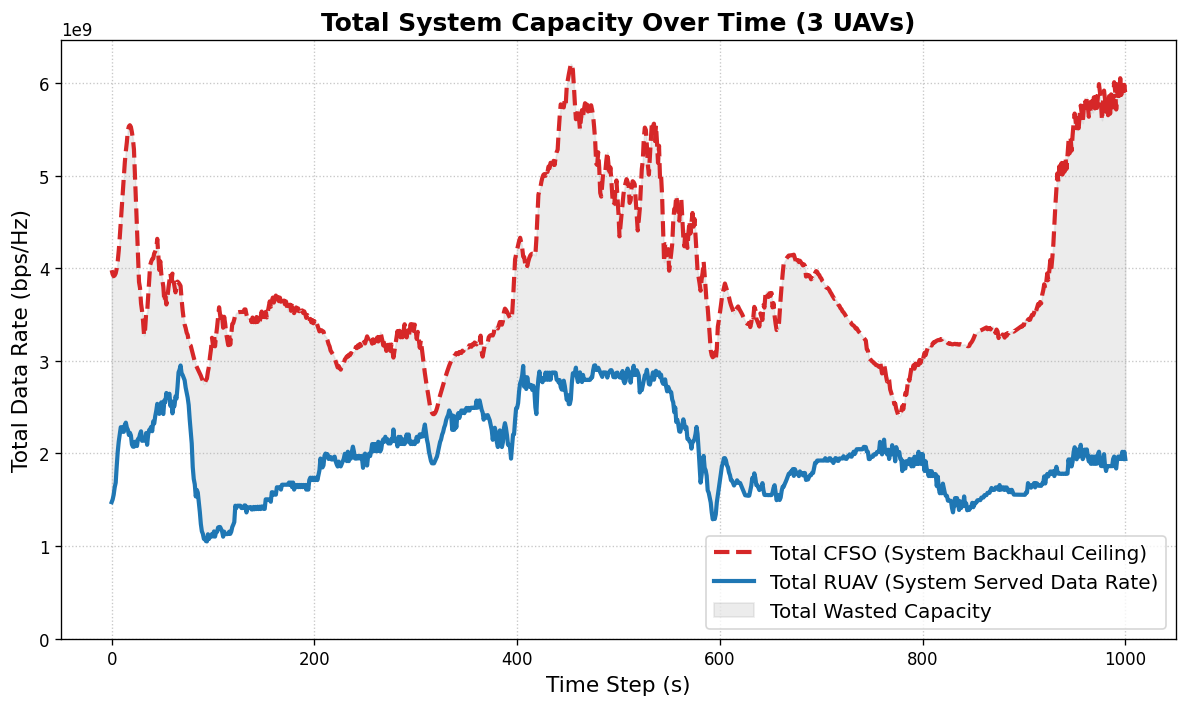

Hoàn tất đánh giá!


In [4]:
import torch
import torch.nn as nn
import torch.optim as optim
# from System_Modeling_update_obs_vec import * 
from collections import deque
from tqdm import trange 
import random 
import matplotlib.pyplot as plt
import matplotlib.animation as animation
import matplotlib.patches as patches
import numpy as np
import torch.nn.functional as F
import Channel_FSO as ch_fso 
# import Channel_RF as ch_rf
from Parameters import *
import os 
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

action_size = 5
STEP  = 20 
batch_size = 64
gamma = 0.99 # discounted factor
epsilon_start = 1.0
epsilon_min = 0.05
n_episodes = 1251
n_steps = 300
n_steps_test=1000
epsilon_decay  = (epsilon_start - epsilon_min) / (1/6 * n_episodes * n_steps)  
# 2/3 total step is exploration, the rest of step is exploitation
# epsilon_start - (2/3 * n_episodes * n_steps * x ) < epsilon_min => x = 2.375e-5
learning_rate = 1e-3
n_uavs = 3
n_users = 200

class DQN(nn.Module):
    """
    Deep Q-Network for UAV model

    Agrs:
        n_observation (int): observation vector for input
        n_action (int)     : UAV action
    
    Returns:
        the best action in each observation vector 
    """
    def __init__(self, n_observation, n_action):
        super().__init__()
        self.linear_relu_stack = nn.Sequential (
            nn.Linear(n_observation, 256),
            nn.ReLU(),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, n_action)
        )
    def forward(self, x):
        return self.linear_relu_stack(x)

def move_uav(uav_pos, action):
    """
    Action Space:
        Discrere space: the numver of possible action is finite (5)
    
    Args:
        uav_pos : uav position in tensor [(n_uavs , 2)]
        action  (int): specific number representing for action 
    
    Returns:
        uav_pos after performing action    
    """
    moved = uav_pos.clone()
    for i,a in enumerate (action):
        if a==0: moved[i][0] += STEP  # moving 1 step East 
        elif a == 1: moved[i][0] -= STEP # West
        elif a == 2: moved[i][1] += STEP # North
        elif a == 3: moved[i][1] -= STEP  # South
        else :
            pass
        moved[i][0] = torch.clip(moved[i][0],0, map_maximum_xy_axis - 1)
        moved[i][1] = torch.clip(moved[i][1],0, map_maximum_xy_axis - 1)
    return moved

def simulate_user_mobility(
        n_users, n_steps,
        distribution='gaussian', n_hotspot = n_uavs,
        ratio_mobile = 0.2,
        device ="cuda", 
        dtype = torch.float32
        ):

    """
    Simulate user mobility with 20% of them will move, while the rest
    is standing (not moving) 

    Args: 
        n_users (int) : Number of users
        n_steps (int) : Number of time steps
        map_center (float): Half of the area size 
        distribution (str) : User mobility models
        n_hotspot (int) : Number of hotspots 
        ratio_mobile (float) : Ratio of moving users and total one
    Returns:
        positions: np.ndarray of shape (n_users, n_steps, 2) 
    """

    positions = np.zeros((n_users, n_steps, 2))  
    n_mobile  = int(ratio_mobile * n_users)
    mobile_indices = np.random.choice(n_users, n_mobile, replace=False)
    static_indices = [i for i in range(n_users) if i not in mobile_indices]

    if distribution == 'gaussian':

        if n_hotspot > 1 :
            spot_centers = []

            for _ in range(n_hotspot):
                mean = np.random.uniform(300, map_center * 2 - 300,2)   
                spot_centers.append(mean)       
            spot_users = [0]

            while any(np.array(spot_users) <=0 ):
                nums = np.random.normal(n_users // n_hotspot,20,size= n_hotspot)
                spot_users = [int(num) for num in nums]
                spot_users[-1] = n_users - sum(spot_users[:-1])
            idx = 0

            for i in range(n_hotspot):
                count = spot_users[i]          
                group = np.arange(idx, idx+ count)  
                init_pos = np.random.normal(spot_centers[i], 200, (count, 2)) 
                positions[group, 0, :] = init_pos 
                idx +=count 

        else:
            mean = np.random.uniform(300, map_center * 2 -300, 2)
            positions[:,0,:] = np.random.normal(mean, 300, (n_users,2))
    elif distribution == 'uniform':
        positions[:,0,:] = np.random.uniform(0,map_center*2, (n_users, 2))


    # Clip initial positions to boundaries in map 
    positions[:,0,:] = np.clip(positions[:,0,:], 0, map_center * 2)
    positions[static_indices,:,:] = positions[static_indices, 0, :][:,None,:]

    alpha = 0.75
    avg_speed = 1.358 #m/s Men who is (20-29) age years old.  
    delta_t = 1.0 
    speeds = np.zeros(n_users)
    directions = np.random.uniform(low=0, high=360,size=n_users)
    avg_direction = directions.copy()

    
    for t in range(1,n_steps):

        s_x = np.random.normal(0,1, size=n_mobile)
        d_x = np.random.normal(0,1, size=n_mobile)

        speeds[mobile_indices]     = (alpha * speeds[mobile_indices]     + (1-alpha)* avg_speed                     + np.sqrt((1-alpha**2))*s_x)
        directions[mobile_indices] = (alpha * directions[mobile_indices] + (1-alpha)* avg_direction[mobile_indices] + np.sqrt((1-alpha**2))*d_x)

        pre_x = positions[mobile_indices, t-1, 0]
        pre_y = positions[mobile_indices, t-1, 1]

        new_x = np.round(pre_x + speeds[mobile_indices]* np.cos(np.deg2rad(directions[mobile_indices])) * delta_t ,2)
        new_y = np.round(pre_y + speeds[mobile_indices]* np.sin(np.deg2rad(directions[mobile_indices])) * delta_t ,2)
        
        limit_map = map_center * 2
        out_right = new_x > limit_map
        out_left  = new_x < 0
        out_top   = new_y > limit_map
        out_bot   = new_y < 0

        corner_upper_right = out_right & out_top        
        avg_direction[mobile_indices[corner_upper_right]] = 225
        new_x[corner_upper_right], new_y[corner_upper_right] = limit_map, limit_map

        corner_upper_left = out_left & out_top
        avg_direction[mobile_indices[corner_upper_left]] = 315
        new_x[corner_upper_left], new_y[corner_upper_left] = 0, limit_map

        corner_lower_right = out_right & out_bot
        avg_direction[mobile_indices[corner_lower_right]] = 135
        new_x[corner_lower_right], new_y[corner_lower_right] = limit_map, 0

        corner_lower_left = out_left & out_bot
        avg_direction[mobile_indices[corner_lower_left]] = 45
        new_x[corner_lower_left], new_y[corner_lower_left] = 0, 0

        edge_right = out_right & ~out_top & ~out_bot
        avg_direction[mobile_indices[edge_right]] = 180
        new_x[edge_right] = limit_map

        edge_left = out_left & ~out_top & ~out_bot
        avg_direction[mobile_indices[edge_left]] = 0 
        new_x[edge_left] = 0

        edge_top = out_top & ~out_right & ~out_left
        avg_direction[mobile_indices[edge_top]] = 270
        new_y[edge_top] = limit_map

        edge_bot = out_bot & ~out_right & ~out_left
        avg_direction[mobile_indices[edge_bot]] = 90
        new_y[edge_bot] = 0


        positions[mobile_indices, t, 0] = new_x
        positions[mobile_indices, t, 1] = new_y

    postions_3d = np.zeros((n_users, n_steps, 3))
    postions_3d[:,:,:2] = positions

    return torch.tensor(postions_3d,dtype=dtype,device=device)

def plot_user(user_positions, time_step=1):
    fig, ax = plt.subplots(figsize=(8, 8))
    ax.scatter(user_positions[:,time_step,0], user_positions[:,time_step,1], color='blue', s=8, label='Users')
    ax.set_xlim(0, map_maximum_xy_axis)
    ax.set_ylim(0, map_maximum_xy_axis)
    ax.legend()
    ax.set_xlabel("X")
    ax.set_ylabel("Y")
    plt.grid(True)
    plt.tight_layout()
    plt.show()


def build_user_heatmap(user_pos_t, device= "cuda"):
    """
    Build user heatmap from their position at time step t 

    Args:
        user_pos_t ((num_users, t, 2))
    
    Returns:
        User heatmap at specified time step ((n_cells, n_cells))
    """
    xy = user_pos_t[:,:2]
    indices = (xy / map_cell_size).long()
    indices = torch.clamp(indices, min =0, max=n_cells-1) 
    cols = indices[:,0]
    rows = indices[:,1] 
    flat_indices = rows * n_cells + cols  
    heatmap_1d = torch.bincount(flat_indices, minlength=n_cells*n_cells).float()
    heatmap = heatmap_1d.view(n_cells, n_cells)
    max_val = heatmap.max()

    if max_val > 0 :
        heatmap = heatmap / max_val
        
    return heatmap
    

def torch_get_full_cloud(clwc_range=[0.5, 7.5], device="cuda"):
    # 1. Tạo ma trận ngẫu nhiên siêu nhỏ: 6 ô dọc x 8 ô ngang
    small_noise = torch.rand((1, 1, 6, 8), device=device)
    
    # 2. Phóng to lên (1600x6400) bằng bicubic -> Mây tự mượt, không bị lốm đốm
    cloud = F.interpolate(small_noise, size=(1600, 6400), mode='bicubic', align_corners=False)
    
    # 3. Mũ 2 để đè các vùng mây mờ xuống -> Tạo thung lũng trời quang rộng lớn
    cloud = cloud ** 2
    
    # 4. Đưa về thang giá trị [0.5 -> 7.5]
    cloud_map = clwc_range[0] + cloud * (clwc_range[1] - clwc_range[0])
    cloud_map = torch.clamp(cloud_map, min=clwc_range[0], max=clwc_range[1])

    return cloud_map




def get_cloudmap_t(t, cloud_map,device="cuda"):
    """
    Get cloud map at time step t in the coordinate origin (1600, 1600)

    Args:
        t (int) : time step 
        concentrated_cloud_map (area): the cloud map which is stack by a number of its copy

    Returns:
        region_t ((area, area)): cloud map at time step t 
        cell_clwc_t ((n_cells, n_cells)): clwc value calculated in cells  
    """
    shift = int(4 * t)
    region_t = cloud_map[0,0,:,shift:shift+map_maximum_xy_axis]
    region_t_4D = region_t.unsqueeze(0).unsqueeze(0)

    cell_clwcl_t = F.avg_pool2d(
        region_t_4D,
        kernel_size=map_cell_size,
        stride=map_cell_size)
    
    cell_clwcl_t = cell_clwcl_t.squeeze() / 7.5

    return region_t, cell_clwcl_t



def cal_probability_having_LoS(vertical_dist, horizontal_dist):
    return (
        1 / (1 + a*torch.exp(-b*(180/torch.pi* torch.arctan(vertical_dist/horizontal_dist)) -a))
    )

def cal_avg_pathloss(dist_3d, p_LoS, current_fc):
    #cal path loss LoS and NLoS
    eta_LoS = 20* torch.log10(4*torch.pi*current_fc*dist_3d/ c) + xi_los
    eta_NLoS = 20* torch.log10(4*torch.pi*current_fc*dist_3d/ c) + xi_nlos

    return (
       p_LoS * eta_LoS + (1- p_LoS)*eta_NLoS
    )

def cal_dbW(dbm):
    return (
        10 ** ((dbm-30)/10)
    )
    


def cal_R_FP_batch(ue_pos_t, fp_pos,base_station='uav',device='cuda', 
                   B_RF=600e6, fc = 2e9):
    """
    Calculate Data Rate betweeen Flying Platforms (uav/hap) and users
    
    Agrs:
        ue_pos_t : user position at time step t
        fp_pos   : flying platform position
    """
    # Old: d = torch.norm(user_pos[:, :2].unsqueeze(1) - fp_pos[:, :2].unsqueeze(0), dim=2)  # (N, M)
    # New :
    if base_station == 'uav':
        vertical_dist = uav_z
        horizontal_dist = torch.linalg.norm(ue_pos_t[:,:2].unsqueeze(1) - fp_pos[:,:2],dim=2) # ([n_user, n_uav])

    elif base_station == 'hap':
        vertical_dist = hap_z
        horizontal_dist = torch.linalg.norm(ue_pos_t[:,:2].unsqueeze(1) - fp_pos[:2],dim=2) # ([n_user, 1])

    else :
        print(f"no base station was chosen")
        return -1
    
    dist_3d = torch.sqrt(horizontal_dist**2 + vertical_dist**2)

    P_los = cal_probability_having_LoS(vertical_dist , horizontal_dist )
    avg_eta = cal_avg_pathloss(dist_3d= dist_3d , p_LoS= P_los,current_fc= fc)

    avg_eta_exponent = 10** (-avg_eta / 10)

    N0_W_HZ = cal_dbW(N0)
    if base_station == 'uav':
        P_RF_W = cal_dbW(UAV_P_RF)
    elif base_station == 'hap':
        P_RF_W = cal_dbW(HAP_P_RF)
    else :
        print(f"no base station was chosen")
        return -1
    
    SNR = P_RF_W * avg_eta_exponent /  N0_W_HZ
    data_rate   = (B_RF / n_users) * torch.log2(1+SNR)

    return data_rate


def perform_user_association(uav_pos, user_pos_t, region_t, HAP_position, device ="cuda"):
    """
    Perform user association based on valid UAV range and capacity.

    Args:
        uav_pos  tensor ((num_uav, 3))          # 3 stands for x,y,z value in coordinate origin
        user_pos_t tensor ((num_users, num_step, 3))  # 3 stands for x,y,z value in coordinate origin
        region_t tensor ((area, area))
        HAP_position tensor ((1 , 3))           # 3 stands for x,y,z value in coordinate origin

    Returns:
        alpha: UE/UAV association matrix ((num_users, num_uav))
        beta : UE/HAP association tensor (num_users)
        RUAV : Total Rate per UAV       (num_uav)    
        CFSO : FSO Capacity per UAV     (num_uav)
    """
    with torch.no_grad():
        x_idx = uav_pos[:, 0].long().clamp(0, region_t.shape[1]-1)
        y_idx = uav_pos[:, 1].long().clamp(0, region_t.shape[0]-1)
        Mc = region_t[y_idx, x_idx]
        CFSO = ch_fso.Ergodic_Capacity_Trapz(
            x_higher_vehicle=HAP_position[0], y_higher_vehicle=HAP_position[1], z_higher_vehicle=HAP_position[2],
            x_lower_vehicle=uav_pos[:,0], y_lower_vehicle=uav_pos[:,1], z_lower_vehicle=uav_pos[:,2],
            Mc=Mc,link='HAP-UAV'
        )

        CFSO_remaining = CFSO.clone()
        dists = torch.linalg.norm(user_pos_t[:,:2].unsqueeze(1) - uav_pos[:,:2],dim=2) #([n_users, n_uavs])
        is_user_in_uav_range = dists <= uav_radius_coverage
        all_uav_rates = cal_R_FP_batch(ue_pos_t=user_pos_t, fp_pos= uav_pos, base_station='uav')
        hap_rates     = cal_R_FP_batch(ue_pos_t=user_pos_t, fp_pos= HAP_position, base_station='hap')
        is_uav_rate_better_than_hap = all_uav_rates > hap_rates
        valid = is_user_in_uav_range & is_uav_rate_better_than_hap  #([n_user, n_uav])
        alpha = torch.zeros((n_users,n_uavs), dtype=torch.bool,device=device)
        beta  = torch.ones(n_users, dtype=torch.bool,device=device)
        RUAV =  torch.zeros(n_uavs, dtype=torch.float32,device=device)
        valid_rates = valid * all_uav_rates
        sorted_rates, sorted_uav = torch.sort(valid_rates,dim=1,descending=True)

        for user_idx in range(n_users):
            for i in range(n_uavs):
                rate = sorted_rates[user_idx,i].item() #return float instead of tensor with one element

                if rate <=0 :
                    break

                uav_idx = sorted_uav[user_idx, i]

                if CFSO_remaining[uav_idx].item() >=rate :
                    alpha[user_idx,uav_idx] =True
                    beta[user_idx] = False
                    RUAV[uav_idx] +=rate
                    CFSO_remaining[uav_idx] -=rate
                    break # Next user 


        return alpha, beta, RUAV, CFSO
                

def build_observation_vector(uav_pos, user_pos_t, cell_clwc_t, alpha, beta, device="cuda"):
    """
    Build the observation input vector (a.k.a Observation Space)

    Args: 
        uav_pos  (( num_uav, 3)) : Position of each UAV in 3 dimensions torch
        user_pos_t : Position of users in a specific time step
        cell_clwc_t (( n_cells, n_cells)): cell clwc value
        alpha    (( num_users, num_uav))
        beta     (num_uav) 
    Returns:
        Observation space vector with shape torch.Tensor ((3,130))
    """

    obs_list = []
    normalized_uav_xy = uav_pos[:,:2] / map_maximum_xy_axis
    
    for i in range(n_uavs):
        served_mask = (alpha[:, i] ==1 ) | (beta ==1)   # | is OR operator        
        served_users_xy = user_pos_t[served_mask]
        user_heatmap = build_user_heatmap(served_users_xy) 
        other_uav_pos = torch.cat([normalized_uav_xy[:i], normalized_uav_xy[i+1:]])
        obs_vector  = torch.concatenate([normalized_uav_xy[i],other_uav_pos.flatten(), user_heatmap.flatten(), cell_clwc_t.flatten()])
        obs_list.append(obs_vector)
    obs_batch = torch.stack(obs_list, axis=0)

    return obs_batch


def calculate_rewards(RUAV, CFSO, uav_pos, Rthres=0.6e9, w=0.3 , p=0.5, device ="cuda"):
    """
    Reward Function: 
        Calculate rewards based on user association results. This stage is fundemental 
        in RL because it is the only feedback for the agent. Thanks to it, out agent knows
        if the action taken was good or not.

    Args:
        RUAV: Total rate per UAV (tensor)
        CFSO: FSO Capacity per UAV (tensor)
        uav_pos: Position of each UAV in 3 dimensions tensor (( num_uav, 3))
        Rthres: Rate threshold
        w: Global reward weight 
        p: overlap penalty

    Returns:
        rewards: List of rewards for each UAV
    """

    with torch.no_grad():
        num_uav = CFSO.shape[0]
        if not isinstance(Rthres, torch.Tensor):
            Rthres = torch.tensor(Rthres, device=device)

        # UAV overlaps
        delta = uav_pos[:,:2].unsqueeze(1) - uav_pos[:,:2].unsqueeze(0)
        dists_uav = torch.linalg.norm(delta, dim =2)
        overlaps = (dists_uav < 2* uav_radius_coverage) & (~torch.eye(n=num_uav, device=device, dtype=torch.bool))
        nc = overlaps.sum(dim=1)

        # global reward 
        total_rate = torch.sum(RUAV)
        total_capacity = torch.sum(CFSO)
        thres = num_uav * Rthres
        sqrt_sum = torch.sqrt((total_rate * total_capacity/ thres**2))
        g_reward = sqrt_sum - (0.0 if torch.all(RUAV > Rthres) else 1.0)

        # local reward 
        sqrt_term = torch.sqrt((RUAV / Rthres) * (CFSO/Rthres))
        l_reward  = torch.where(RUAV > Rthres, sqrt_term -nc*p, sqrt_term - nc*p -1) 

        #total reward
        total_reward = w * g_reward + (1-w) * l_reward

        return total_reward.tolist()


def user_association_and_calculate_reward(uav_pos, user_pos_t, region_t, HAP_position ,device ="cuda"):
    """
    Perform user association, then calculate reward (combining perform_user_association and calculating rewards functions) 

    Args:
        uav_pos: UAV position (tensor)
        user_pos_t: user position at time step t (tensor)
        region_t: clwc map at time step t 
        HAP_position: HAP position (tensor)

    Returns:
        rewards : 
        alpha: UE/UAV association matrix ((num_users, num_uav))
        beta : UE/HAP association tensor (num_users)
        RUAV : Total Rate per UAV       (num_uav)
        CFSO : FSO Capacity per UAV (num_uav)    
    """

    alpha, beta, RUAV, CFSO = perform_user_association(uav_pos, user_pos_t, region_t,HAP_position,device=device)
    rewards = calculate_rewards(RUAV, CFSO,uav_pos,device=device)

    return rewards, alpha, beta, RUAV, CFSO


def build_observation_vector(uav_pos, user_pos_t, cell_clwc_t, alpha, beta, device="cuda"):
    """
    Build the observation input vector (a.k.a Observation Space)

    Args: 
        uav_pos  (( num_uav, 3)) : Position of each UAV in 3 dimensions torch
        user_pos_t : Position of users in a specific time step
        cell_clwc_t (( n_cells, n_cells)): cell clwc value
        alpha    (( num_users, num_uav))
        beta     (num_uav) 
    Returns:
        Observation space vector with shape torch.Tensor ((3,130))
    """

    obs_list = []
    normalized_uav_xy = uav_pos[:,:2] / map_maximum_xy_axis

    if (n_uavs==1):
        served_mask = (alpha[:,0] ==1 ) | (beta ==1)   # | is OR operator   
        # print(served_mask.shape)     
        served_users_xy = user_pos_t[served_mask]
        user_heatmap = build_user_heatmap(served_users_xy) 
        # other_uav_pos = torch.cat([normalized_uav_xy[:i], normalized_uav_xy[i+1:]])
        obs_vector  = torch.concatenate([normalized_uav_xy.flatten(), user_heatmap.flatten(), cell_clwc_t.flatten()])
        obs_list.append(obs_vector)

        obs_batch = torch.stack(obs_list, axis=0)
    else :
        for i in range(n_uavs):
            served_mask = (alpha[:, i] ==1 ) | (beta ==1)   # | is OR operator        
            # print(served_mask.shape)     

            served_users_xy = user_pos_t[served_mask]
            user_heatmap = build_user_heatmap(served_users_xy) 
            other_uav_pos = torch.cat([normalized_uav_xy[:i], normalized_uav_xy[i+1:]])
            obs_vector  = torch.concatenate([normalized_uav_xy[i],other_uav_pos.flatten(), user_heatmap.flatten(), cell_clwc_t.flatten()])
            obs_list.append(obs_vector)
        obs_batch = torch.stack(obs_list, axis=0)

    return obs_batch

def train(device=device):

    total_cells = (map_maximum_xy_axis // map_cell_size) **2
    Q_nets = [DQN(2*n_uavs+total_cells*2,action_size).to(device) for i in range(n_uavs)]   #    2 + total_cells**2 is equal the number of length [x_uav, y_uav, user heatmap, cloud heatmap]
    target_Q_nets = [DQN(2*n_uavs+total_cells*2,action_size).to(device) for i in range(n_uavs)]

    for i in range(n_uavs):
        target_Q_nets[i].load_state_dict(Q_nets[i].state_dict())
        for param in target_Q_nets[i].parameters():
            param.requires_grad = False

    optimizers = [optim.Adam(Q_nets[i].parameters(), lr=learning_rate) for i in range(n_uavs)] 
    replay_buffers = [deque(maxlen=1_000_000) for _ in range(n_uavs)]
    hap_pos = torch.tensor([map_maximum_xy_axis/2, map_maximum_xy_axis/2,hap_z], dtype= torch.float32,device=device)
    total_step = 0
    episode_return = []

    for episode in trange(n_episodes):
        cloud_map = torch_get_full_cloud() # tensor ([1600, 6400])
        # cloud_map =  torch.empty(
        #     size=(n_cells, n_cells*4), dtype=torch.float32, device="cuda"
        #     ).fill_(0.5)
        # cloud_map = F.interpolate(
        #     cloud_map.unsqueeze(0).unsqueeze(0),
        #     size = (map_maximum_xy_axis, map_maximum_xy_axis*4),
        #     mode="bicubic")
        
        user_pos = simulate_user_mobility(n_users,n_steps)
        uav_pos = torch.randint(0,map_maximum_xy_axis, (n_uavs, 3),dtype=torch.float32, device=device )
        uav_pos[:,2] = uav_z
        total_rewards = torch.zeros(n_uavs)
        total_loss    = torch.zeros(n_uavs)
        loss_counts   = torch.zeros(n_uavs)
        
        # Gemini feedback: initialize time step 0 here 
        region_0, cell_clwc_0 = get_cloudmap_t(0,cloud_map)
        user_pos_0 = user_pos[:,0,:]
        _, alpha0, beta0, _ ,_= user_association_and_calculate_reward(
            uav_pos, user_pos_0, region_0, hap_pos,device
        )
        # print(alpha0.shape)
        obs_vec = build_observation_vector(
            uav_pos, user_pos_0, cell_clwc_0, alpha0, beta0
            ) # ([3,134]) # 3 stands for n_uavs, 134 stands for obs_vec length

        for t in range(n_steps):
            total_step +=1
            actions = []
            epsilon = max(epsilon_min, epsilon_start - total_step * epsilon_decay)
            for i in range(n_uavs):
                # if random.random()
                if random.random() < epsilon :
                    actions.append(random.randint(0, action_size -1)) 
                else :
                    with torch.no_grad():
                        q_values = Q_nets[i](obs_vec[i])
                        actions.append(q_values.argmax().item())

            uav_pos = move_uav(uav_pos, actions)
            next_t = min(t+1,n_steps-1)
            next_region_t, next_cell_clwc_t = get_cloudmap_t(next_t, cloud_map)
            next_user_pos_t = user_pos[:,next_t,:]

            rewards, alpha, beta, _,_ = user_association_and_calculate_reward(
                uav_pos, next_user_pos_t, next_region_t, hap_pos,device
                )
            next_obs_vec = build_observation_vector(
                uav_pos, next_user_pos_t,next_cell_clwc_t, alpha,beta
                ) # ([3,130]) # 3 stands for n_uavs, 130 stands for obs_vec length 

            for i in range(n_uavs):
                done = 1.0 if t == n_steps -1 else 0.0
                replay_buffers[i].append((obs_vec[i].detach().cpu(), actions[i], rewards[i], next_obs_vec[i].detach().cpu(), done))

            total_rewards += torch.tensor(rewards)

            for i in range(n_uavs):
                if (len(replay_buffers[i]) >= batch_size ):
                    minibatch = random.sample(replay_buffers[i], batch_size) # lấy mẫu
                    states = torch.stack([s[0] for s in minibatch]).to(device) # thêm các hàm trạng thái
                    actions_batch = torch.tensor([s[1] for s in minibatch], dtype=torch.long, device=device) # 
                    rewards_batch = torch.tensor([s[2] for s in minibatch], dtype=torch.float32, device=device)
                    next_states = torch.stack([s[3] for s in minibatch]).to(device)
                    dones_batch = torch.tensor([s[4] for s in minibatch], dtype=torch.float32, device=device)

                    with torch.no_grad():
                        next_q = target_Q_nets[i](next_states)  # torch 
                        max_next_q_values = next_q.max(1).values
                        y = rewards_batch +  (1-dones_batch) * gamma * max_next_q_values
                        y = y.unsqueeze(1)
                        
                    Q_values = Q_nets[i](states).gather(1,actions_batch.unsqueeze(1))
                    loss = nn.SmoothL1Loss()(Q_values, y)
                    optimizers[i].zero_grad()
                    loss.backward()
                    torch.nn.utils.clip_grad_value_(Q_nets[i].parameters(), clip_value=1.0)
                    optimizers[i].step()      
                    total_loss[i] +=loss.item()
                    loss_counts[i] +=1
                    
            # Reset target Q == Q for every fix 100 steps
            if total_step % 100 ==0:
                for i in range(n_uavs):
                    target_Q_nets[i].load_state_dict(Q_nets[i].state_dict()) 

        
            obs_vec = next_obs_vec

        episode_return.append(total_rewards.clone().cpu().numpy())

        if episode % 250 == 0:
            avg_reward = torch.mean(total_rewards).item()
            avg_loss = torch.mean(total_loss/ loss_counts +1e-9).item()
            print(f"Episode: {episode}/{n_episodes} | "
                  f"Epsilon: {epsilon:.3f} | "
                  f"Avg Reward: {avg_reward:.2f} | "
                  f"Avg Loss: {avg_loss:.4f}")
            
            save_dir = '/kaggle/working/save_models'
            os.makedirs(save_dir, exist_ok= True)

            for i in range(n_uavs):
                torch.save(Q_nets[i].state_dict(), os.path.join(save_dir,f"q_net_uav{i}_ep{episode}.pt"))
                # torch.save(target_Q_nets[i].state_dict(), os.path.join(save_dir, f"target_q_net_uav{i}_ep{episode}.pt"))
                # torch.save(optimizers[i].state_dict(), os.path.join(save_dir,f"optimizer_uav{i}_ep{episode}.pt"))

            print(f"Model and training state saved at episode {episode}\n")
    print(f"OK Models saved successfully\n")
    return episode_return

def evaluate_trained_policy(
    device=device, 
    save_dir = "/kaggle/input/models/trisleevawnminh/agin2/pytorch/default/1",
    episode_to_load =str(n_episodes-1),
    n_steps_test= n_steps_test
):
    """
    Evaluate trained policy

    Args:
        DQN: Deep Q Network that is used to train 
        action_size: action size of UAV
        n_uavs: number of uav
        n_steps_test: total steps to test
        uav_pos_init: initial uav position
        user_pos: user position
        cloud_map: cloud map 
        hap_pos: hap position 
        episode to load: which episode to evaluate 
        save_dir: save directory in kaggle 
    
    Returns:
        RUAV_log: Total Data Rate served by UAV
        CFSO_log: Allocated FSO to UAV
        uav_traj: uav trajectory 
    """
    total_cells = (map_maximum_xy_axis // map_cell_size) **2
    Q_nets = [DQN(2*n_uavs+total_cells*2,action_size).to(device) for i in range(n_uavs)]   #    2 + total_cells**2 is equal the number of length [x_uav, y_uav, user heatmap, cloud heatmap]

    for i in range(n_uavs):
        path = f"{save_dir}/q_net_uav{i}_ep{episode_to_load}.pt"
        Q_nets[i].load_state_dict(torch.load(path, map_location = device))
        Q_nets[i].eval()

    # torch.manual_seed(1)
    # Some parameter used for testing only 
    hap_pos = torch.tensor([map_maximum_xy_axis/2, map_maximum_xy_axis/2,hap_z], dtype= torch.float32,device=device)
    cloud_map = torch_get_full_cloud()
    
    # cloud_map =  torch.empty(
    #     size=(n_cells, n_cells*4), dtype=torch.float32, device="cuda"
    #     ).fill_(0.5)
    # cloud_map = F.interpolate(
    #     cloud_map.unsqueeze(0).unsqueeze(0),
    #     size = (map_maximum_xy_axis, map_maximum_xy_axis*4),
    #     mode="bicubic")
    
    user_pos = simulate_user_mobility(n_users, n_steps_test)
    uav_pos = torch.randint(0,map_maximum_xy_axis, (n_uavs, 3),dtype=torch.float32, device=device )
    uav_pos[:,2] = uav_z

    region_0, cell_clwc_0 = get_cloudmap_t(0,cloud_map)
    user_pos_0 = user_pos[:,0,:]
    rewards0, alpha0, beta0, RUAV0, CFSO0 = user_association_and_calculate_reward(
        uav_pos, user_pos_0, region_0, hap_pos,device
    )
    obs_vec = build_observation_vector(
        uav_pos, user_pos_0, cell_clwc_0, alpha0, beta0
        ) # ([3,130]) # 3 stands for n_uavs, 130 stands for obs_vec length

    uav_rewards, RUAV_log, CFSO_log, uav_traj, alpha_log = [],[],[],[],[]
    uav_rewards.append(rewards0)
    RUAV_log.append(RUAV0)
    CFSO_log.append(CFSO0)
    uav_traj.append(uav_pos.cpu().numpy().copy())
    alpha_log.append(alpha0)
    
    for t in range(n_steps_test):
        with torch.no_grad():
            actions = [Q_nets[i](obs_vec[i]).argmax().item() for i in range(n_uavs)]

        uav_pos = move_uav(uav_pos, actions)
        next_t = min(t+1, n_steps_test -1)
        next_region_t, next_cell_clwc_t = get_cloudmap_t(next_t, cloud_map)
        next_user_pos_t = user_pos[:,next_t,:]
        rewards, alpha, beta, RUAV, CFSO = user_association_and_calculate_reward(
            uav_pos, next_user_pos_t, next_region_t, hap_pos, device
        )

        obs_vec = build_observation_vector(
            uav_pos, next_user_pos_t, next_cell_clwc_t,alpha, beta
            )
        uav_rewards.append(rewards)
        RUAV_log.append(RUAV)
        CFSO_log.append(CFSO)
        uav_traj.append(uav_pos.cpu().numpy().copy())
        alpha_log.append(alpha)
    return RUAV_log, CFSO_log, uav_traj, uav_rewards, cloud_map, hap_pos, user_pos, alpha_log

def draw_gif(t):

    # ==== Màu sắc đại diện ====
    uav_colors = ['blue', 'yellow', 'green']
    hap_color = 'red'

    # ==== Vẽ animation ====

    ax.clear()
    ax.set_xlim(0, map_maximum_xy_axis)
    ax.set_ylim(0, map_maximum_xy_axis)
    ax.set_xlabel("x (m)")
    ax.set_ylabel("y (m)")
    ax.grid(True)
    ax.set_title(f"Time step {t}")
    shift = min(int(4 * t), cloud_map.shape[3] - map_maximum_xy_axis)
    region = cloud_map[0,0,:, shift:shift + map_maximum_xy_axis]
    discrete_cmap = plt.get_cmap('Blues', 7)
    
    img = ax.imshow(
    region,
    cmap=discrete_cmap,              # Hoặc thử 'bone', 'Blues'
    origin='lower',
    extent=[0, 1600, 0, 1600],
    alpha=0.5,
    vmin=0.5,
    vmax=7.5
    )

    # ==== Vẽ HAP ====
    ax.scatter(hap_pos[0], hap_pos[1], marker='s', color=hap_color, label='HAP')
    current_uav_pos = uav_traj[t]
    # ==== Vẽ UAVs và vùng phủ sóng ====
    for i, uav in enumerate(current_uav_pos):
        ax.scatter(uav[0], uav[1], marker='^', color=uav_colors[i], label=f"UAV {i+1}")
        circle = patches.Circle((uav[0], uav[1]), radius=uav_radius_coverage, fill=False, color=uav_colors[i], linestyle='--')
        ax.add_patch(circle)
        
    current_alpha = alpha_log[t]
    if torch.is_tensor(current_alpha):
        current_alpha = current_alpha.cpu().numpy()
    # ==== Vẽ người dùng ====
    for n in range(n_users):
        x, y= user_pos[n, t,:2]
        served = -1
        for i in range(len(current_uav_pos)):
            if current_alpha[n,i]:
                served = i
                break
        if served!= -1:
            user_color = uav_colors[i]
        else :
            user_color = 'gray'
        
        ax.scatter(x, y, marker='o', color=user_color, edgecolors='k', s=20)

    # ==== Gọn legend ====
    handles, labels = ax.get_legend_handles_labels()
    by_label = dict(zip(labels, handles))
    ax.legend(by_label.values(), by_label.keys(), loc='upper right')

def plot_training_rewards(episode_return, window_size =50):
    print("Đang vẽ biểu đồ quá trình huấn luyện (Training Rewards)...")
    returns_arr = []
    for r in episode_return:
        if torch.is_tensor(r):
            returns_arr.append(r.cpu().numpy())
        else:
            returns_arr.append(r)
    returns_arr = np.array(returns_arr, dtype=np.float32)
    n_episodes = returns_arr.shape[0]
    n_uavs = returns_arr.shape[1]
    
    # 2. Khởi tạo đồ thị
    plt.figure(figsize=(10, 6), dpi=120)
    colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd']
    
    # 3. Vẽ đường phần thưởng cho từng UAV
    for i in range(n_uavs):
        uav_rewards = returns_arr[:, i]
        
        # Nếu số episode đủ lớn, áp dụng Moving Average để làm mượt
        if n_episodes >= window_size:
            # Tính trung bình trượt
            weights = np.ones(window_size) / window_size
            smoothed_rewards = np.convolve(uav_rewards, weights, mode='valid')
            
            # Vẽ đường dữ liệu gốc (mờ đi để làm nền)
            plt.plot(uav_rewards, color=colors[i % len(colors)], alpha=0.25)
            # Vẽ đường đã làm mượt (đậm và nổi bật)
            plt.plot(range(window_size - 1, n_episodes), smoothed_rewards, 
                     label=f'UAV {i+1} (Avg {window_size})', 
                     color=colors[i % len(colors)], linewidth=2)
        else:
            # Nếu ít episode quá thì vẽ bình thường
            plt.plot(uav_rewards, label=f'UAV {i+1}', color=colors[i % len(colors)], linewidth=2)

    # 4. Trang trí theo chuẩn bài báo
    plt.title('Training Learning Curve (Episode Rewards)', fontsize=15, fontweight='bold')
    plt.xlabel('Training Episode', fontsize=13)
    plt.ylabel('Average Reward', fontsize=13)
    plt.grid(True, linestyle='-', alpha=0.4)
    plt.legend(loc='lower right', fontsize=11)
    plt.tight_layout()
    
    # 5. Lưu và hiển thị
    save_dir = '/kaggle/working/results'
    os.makedirs(save_dir, exist_ok=True)
    plt.savefig(f'{save_dir}/training_learning_curve.png', bbox_inches='tight')
    plt.show()
    

def plot_evaluation_logs(RUAV_log, CFSO_log, uav_rewards):
    """
    Vẽ 3 biểu đồ đánh giá: Phần thưởng, Dung lượng FSO (CFSO), và Tốc độ phục vụ User (RUAV)
    """
    print("Đang xử lý dữ liệu để vẽ biểu đồ...")
    
    # 1. Chuyển đổi dữ liệu về dạng NumPy mảng 2D: kích thước (n_steps_test, n_uavs)
    # Xử lý trường hợp dữ liệu bên trong vẫn là PyTorch Tensor
    def to_numpy_array(log_data):
        clean_log = []
        for step_data in log_data:
            if torch.is_tensor(step_data):
                clean_log.append(step_data.cpu().numpy())
            elif isinstance(step_data, list) and torch.is_tensor(step_data[0]):
                clean_log.append([x.cpu().item() for x in step_data])
            else:
                clean_log.append(step_data)
        return np.array(clean_log, dtype=np.float32)

    reward_arr = to_numpy_array(uav_rewards)
    cfso_arr = to_numpy_array(CFSO_log)
    ruav_arr = to_numpy_array(RUAV_log)

    n_steps_test = reward_arr.shape[0]
    n_uavs = reward_arr.shape[1]
    steps = np.arange(n_steps_test)

    # 2. Khởi tạo khung vẽ (3 biểu đồ xếp dọc)
    fig, axs = plt.subplots(3, 1, figsize=(12, 12), dpi=100)
    colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd'] # Bảng màu chuẩn

    # --- Biểu đồ 1: Phần thưởng (Rewards) ---
    for i in range(n_uavs):
        axs[0].plot(steps, reward_arr[:, i], label=f'UAV {i+1}', color=colors[i%len(colors)], linewidth=2)
    axs[0].set_title('UAV Rewards Over Time', fontsize=14, fontweight='bold')
    axs[0].set_ylabel('Reward')
    axs[0].grid(True, linestyle='--', alpha=0.7)
    axs[0].legend(loc='upper right')

    # --- Biểu đồ 2: Dung lượng quang học (CFSO) ---
    for i in range(n_uavs):
        axs[1].plot(steps, cfso_arr[:, i], label=f'UAV {i+1}', color=colors[i%len(colors)], linewidth=2)
    axs[1].set_title('FSO Link Capacity', fontsize=14, fontweight='bold')
    axs[1].set_ylabel('CFSO Capacity (bps/Hz)')
    axs[1].grid(True, linestyle='--', alpha=0.7)
    axs[1].legend(loc='upper right')

    # --- Biểu đồ 3: Thông lượng người dùng (RUAV) ---
    for i in range(n_uavs):
        axs[2].plot(steps, ruav_arr[:, i], label=f'UAV {i+1}', color=colors[i%len(colors)], linewidth=2)
    axs[2].set_title('Total Access Link Data Rate', fontsize=14, fontweight='bold')
    axs[2].set_xlabel('Time Step (s)', fontsize=12)
    axs[2].set_ylabel('RUAV Data Rate (bps/Hz)')
    axs[2].grid(True, linestyle='--', alpha=0.7)
    axs[2].legend(loc='upper right')

    # 3. Chỉnh khoảng cách và hiển thị
    plt.tight_layout()
    
    # Nếu chạy trên Kaggle, lưu ảnh ra file trước khi show để phòng bị mất
    plt.savefig('/kaggle/working/results/evaluation_metrics.png', bbox_inches='tight')
    plt.show()

def plot_ruav_vs_cfso(RUAV_log, CFSO_log):
    print("Đang vẽ biểu đồ chồng RUAV lên CFSO...")
    
    # 1. Hàm chuyển đổi dữ liệu an toàn sang NumPy
    def to_numpy_array(log_data):
        clean_log = []
        for step_data in log_data:
            if torch.is_tensor(step_data):
                clean_log.append(step_data.cpu().numpy())
            elif isinstance(step_data, list) and torch.is_tensor(step_data[0]):
                clean_log.append([x.cpu().item() for x in step_data])
            else:
                clean_log.append(step_data)
        return np.array(clean_log, dtype=np.float32)

    cfso_arr = to_numpy_array(CFSO_log)
    ruav_arr = to_numpy_array(RUAV_log)

    n_steps_test = cfso_arr.shape[0]
    n_uavs = cfso_arr.shape[1]
    steps = np.arange(n_steps_test)

    # 2. Khởi tạo khung vẽ (n_uavs biểu đồ xếp dọc)
    fig, axs = plt.subplots(n_uavs, 1, figsize=(12, 4 * n_uavs), dpi=100, sharex=True)
    
    # Ép kiểu list nếu n_uavs = 1 để tránh lỗi khi duyệt vòng lặp
    if n_uavs == 1:
        axs = [axs]

    # 3. Vẽ chồng 2 đường cho từng UAV
    for i in range(n_uavs):
        # Đường CFSO (Trần) - Nét đứt (--), màu đỏ gạch
        axs[i].plot(steps, cfso_arr[:, i], linestyle='--', linewidth=2.5, 
                    color='#d62728', label='CFSO (Ceiling / Backhaul)')
        
        # Đường RUAV (Thực tế) - Nét liền (-), màu xanh lam
        axs[i].plot(steps, ruav_arr[:, i], linestyle='-', linewidth=2, 
                    color='#1f77b4', label='RUAV (Served Data Rate)')
        
        # TÔ MÀU KHOẢNG TRỐNG: Giúp nhìn rõ khoảng cách giữa Trần và Thực tế
        axs[i].fill_between(steps, ruav_arr[:, i], cfso_arr[:, i], 
                            color='gray', alpha=0.15, label='Wasted Capacity')

        # Trang trí biểu đồ
        axs[i].set_title(f'UAV {i+1}: CFSO vs RUAV', fontsize=14, fontweight='bold')
        axs[i].set_ylabel('Data Rate (bps/Hz)')
        axs[i].grid(True, linestyle=':', alpha=0.7)
        axs[i].legend(loc='upper right')

    # Đặt nhãn trục X ở biểu đồ dưới cùng
    axs[-1].set_xlabel('Time Step (s)', fontsize=12)
    
    plt.tight_layout()
    plt.savefig('/kaggle/working/results/ruav_vs_cfso.png', bbox_inches='tight')
    plt.show()

def plot_total_system_capacity(RUAV_log, CFSO_log):
    print("Đang vẽ biểu đồ Tổng dung lượng hệ thống (Total System Capacity)...")
    
    # 1. Hàm chuyển đổi dữ liệu an toàn sang NumPy
    def to_numpy_array(log_data):
        clean_log = []
        for step_data in log_data:
            if torch.is_tensor(step_data):
                clean_log.append(step_data.cpu().numpy())
            elif isinstance(step_data, list) and torch.is_tensor(step_data[0]):
                clean_log.append([x.cpu().item() for x in step_data])
            else:
                clean_log.append(step_data)
        return np.array(clean_log, dtype=np.float32)

    # Chuyển dữ liệu log sang NumPy array
    cfso_arr = to_numpy_array(CFSO_log)
    ruav_arr = to_numpy_array(RUAV_log)

    # Xử lý an toàn: Nếu chỉ có 1 UAV, mảng có thể mất chiều thứ 2, ta ép nó về mảng 2D (n_steps, 1)
    if len(cfso_arr.shape) == 1:
        cfso_arr = cfso_arr.reshape(-1, 1)
        ruav_arr = ruav_arr.reshape(-1, 1)

    n_uavs = cfso_arr.shape[1]
    
    # 2. TÍNH TỔNG TOÀN HỆ THỐNG TẠI MỖI THỜI ĐIỂM
    total_cfso = np.sum(cfso_arr, axis=1)
    total_ruav = np.sum(ruav_arr, axis=1)
    steps = np.arange(len(total_cfso))

    # 3. Khởi tạo khung vẽ đồ thị
    plt.figure(figsize=(10, 6), dpi=120)

    # Đường Tổng CFSO (Trần băng thông của cả hệ thống) - Nét đứt màu đỏ
    plt.plot(steps, total_cfso, linestyle='--', linewidth=2.5, 
             color='#d62728', label='Total CFSO (System Backhaul Ceiling)')
    
    # Đường Tổng RUAV (Lưu lượng thực tế phục vụ) - Nét liền màu xanh lam
    plt.plot(steps, total_ruav, linestyle='-', linewidth=2.5, 
             color='#1f77b4', label='Total RUAV (System Served Data Rate)')
    
    # TÔ MÀU KHOẢNG TRỐNG: Thể hiện lượng băng thông quang học bị lãng phí do UAV không phủ sóng hết
    plt.fill_between(steps, total_ruav, total_cfso, 
                     color='gray', alpha=0.15, label='Total Wasted Capacity')

    # 4. Trang trí biểu đồ
    plt.title(f'Total System Capacity Over Time ({n_uavs} UAVs)', fontsize=15, fontweight='bold')
    plt.xlabel('Time Step (s)', fontsize=13)
    plt.ylabel('Total Data Rate (bps/Hz)', fontsize=13)
    
    # Đặt giá trị nhỏ nhất của trục Y về 0 để nhìn đúng tỷ lệ phần trăm lãng phí
    plt.ylim(bottom=0)
    
    plt.grid(True, linestyle=':', alpha=0.7)
    plt.legend(loc='lower right', fontsize=12)

    plt.tight_layout()
    
    # 5. Lưu và hiển thị
    save_dir = '/kaggle/working/results'
    os.makedirs(save_dir, exist_ok=True)
    plt.savefig(f'{save_dir}/total_system_capacity.png', bbox_inches='tight')
    plt.show()

if __name__ == "__main__":
    # episode_return = train()
     # ==== Lưu thành GIF ====
    save_dir = '/kaggle/working/results'
    os.makedirs(save_dir, exist_ok=True)
    
    print("Bắt đầu vẽ biểu đồ phần thưởng")

    # plot_training_rewards(episode_return, window_size=50) # Cửa sổ 50 episodes để làm mượt
    
    print("Bắt đầu đánh giá mô hình AI...")
    # BỎ COMMENT DÒNG NÀY ĐỂ KẾT NỐI VỚI BỘ NÃO AI
    RUAV_log, CFSO_log, uav_traj, uav_rewards, cloud_map_tensor, hap_pos_tensor, user_pos_tensor, alpha_log = evaluate_trained_policy()
    
    # Ép dữ liệu Tensor từ GPU/CPU về mảng Numpy để Matplotlib vẽ
    cloud_map = cloud_map_tensor.cpu().numpy()
    hap_pos = hap_pos_tensor.cpu().numpy()
    user_pos = user_pos_tensor.cpu().numpy()
    
    # Ghi chú: uav_traj đã là list của numpy arrays ở trong hàm evaluate_trained_policy rồi
    
    print("Đang tạo file Mp4 (vui lòng chờ)...")
    fig, ax = plt.subplots(figsize=(8, 8)) # n_cells có thể gây lỗi nếu chưa định nghĩa, dùng số cụ thể
    
    dummy_cmap = plt.get_cmap('Blues', 7)
    dummy_img = ax.imshow([[0,0],[0,0]], cmap=dummy_cmap, vmin=0.5, vmax=7.5, visible=False)
    cbar = fig.colorbar(dummy_img, ax=ax, fraction=0.046, pad=0.04)
    cbar.set_label('CLWC Value (g/m³)')
    
    
    ani = animation.FuncAnimation(fig, draw_gif,  frames=range(0, n_steps_test, 5))
    
    name_gif = "trained_uav_policy"
    ani.save(f"{save_dir}/{name_gif}.mp4", writer='ffmpeg', fps=10)
    print(f"✅ Đã lưu Video: {save_dir}/{name_gif}.mp4")
    
    # BỎ COMMENT để vẽ các biểu đồ phân tích
    plot_evaluation_logs(RUAV_log, CFSO_log, uav_rewards)
    plot_ruav_vs_cfso(RUAV_log, CFSO_log)
    plot_total_system_capacity(RUAV_log, CFSO_log)
    print("Hoàn tất đánh giá!")
